# Workshop 6 — Medical Domain Adaptation
## 04. WGAN-GP Transfer (Workshop 5) — Synthetic Augmentation

**Course:** Machine Learning — Semester 2026-III
**Team:** Group 1 — Housing Price Prediction → Cardiac Arrhythmia Detection

This notebook transfers the **Workshop 5 WGAN-GP** to generate synthetic
abnormal beats, addressing the critical rarity of severe arrhythmias:

| AAMI class | Beats in dataset | % of total |
|------------|------------------|------------|
| N (Normal) | 90,488 | 89.3% |
| S (Supraventricular) | 2,779 | 2.74% |
| V (Ventricular) | 7,228 | 7.14% |
| **F (Fusion)** | **802** | **0.79%** |

F beats are **125 times rarer** than Normal beats. A supervised model trained
on 694,55 training beats will see only ~550 F examples — insufficient for a
deep network to learn a robust decision boundary.

### Transfer strategy

| Workshop 5 component | Medical adaptation |
|----------------------|--------------------|
| WGAN-GP on 261 housing features | WGAN-GP on 8 medical features |
| Generator + Critic with LayerNorm | Same architecture, adapted dimensions |
| Gradient penalty λ=10 | Same |
| Evaluate with Fréchet distance, KS test | Same |
| Downstream augmentation experiment | Augment MLP training with synthetic beats |

### Key question

**Does WGAN-GP augmentation improve the MLP's ability to detect rare arrhythmias
(F and S) without degrading overall performance?**

In [1]:
import sys
sys.path.append("../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pickle
from pathlib import Path
from torch.utils.data import DataLoader, TensorDataset
from scipy import stats
from sklearn.decomposition import PCA

from medical_preprocessing import FEATURE_COLUMNS, load_splits, fit_scalers, transform
from transfer import (
    set_seed, MedicalMLP, MLPConfig, train_mlp, predict_mlp_proba,
    evaluate_binary, threshold_sweep,
)
from interpretability import save_figure

set_seed(42)
np.random.seed(42)
pd.set_option("display.width", 160)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Device: {DEVICE}")
print(" Imports OK")

Device: cpu
 Imports OK


## 1. Load Data & Extract Rare-Class Training Beats

The WGAN-GP is trained **only on abnormal beats** from the train split (class 1).
We focus on Ventricular (V) beats because they are the most common abnormal
class (7.14%) and clinically the most important (ventricular arrhythmias are
life-threatening).

Fusion (F) beats are too rare (802 total, ~550 in train) to train a stable
GAN — we document this as a limitation.

In [2]:
df = pd.read_csv("../data/features_mitdb.csv")
df["record_id"] = df["record_id"].astype(str)
splits = load_splits("../data/splits_medical.json")

def subset(records):
    sub = df[df["record_id"].isin(records)].reset_index(drop=True)
    return sub

df_train = subset(splits.train_records)
df_val   = subset(splits.val_records)
df_test  = subset(splits.test_records)

# Reload scalers
with open("../results/checkpoints/baselines.pkl", "rb") as f:
    saved = pickle.load(f)
scalers = saved["scalers"]

def to_arrays(sub):
    X = sub[FEATURE_COLUMNS].values.astype(np.float32)
    y = sub["label_binary"].values.astype(np.int64)
    return X, y

X_train, y_train = to_arrays(df_train)
X_val, y_val = to_arrays(df_val)
X_test, y_test = to_arrays(df_test)

X_train_s = transform(X_train, scalers)
X_val_s   = transform(X_val, scalers)
X_test_s  = transform(X_test, scalers)

# Extract V beats from train (most common abnormal)
V_mask_train = (df_train["label_aami"] == "V").values
X_train_V = X_train_s[V_mask_train]

# Also F for reference (very few)
F_mask_train = (df_train["label_aami"] == "F").values
X_train_F = X_train_s[F_mask_train]

print(f"Train total:      {len(X_train_s):,}")
print(f"Train Abnormal:   {(y_train==1).sum():,}")
print(f"  V (Ventricular): {V_mask_train.sum():,}")
print(f"  F (Fusion):      {F_mask_train.sum():,}  ← too rare for stable GAN")
print(f"  S + others:      {(y_train==1).sum() - V_mask_train.sum() - F_mask_train.sum():,}")

# Min-max scaler for GAN (Tanh outputs in [-1, 1])
X_V_min = X_train_V.min(axis=0)
X_V_max = X_train_V.max(axis=0)
X_V_range = np.where(X_V_max - X_V_min > 1e-6, X_V_max - X_V_min, 1.0)

def to_gan_scale(X):
    return 2 * (X - X_V_min) / X_V_range - 1

def from_gan_scale(X_gan):
    return (X_gan + 1) / 2 * X_V_range + X_V_min

X_train_V_gan = to_gan_scale(X_train_V)
print(f"\nV-beat GAN-scale range: [{X_train_V_gan.min():.2f}, {X_train_V_gan.max():.2f}]")

Train total:      69,455
Train Abnormal:   7,483
  V (Ventricular): 4,793
  F (Fusion):      394  ← too rare for stable GAN
  S + others:      2,296

V-beat GAN-scale range: [-1.00, 1.00]


## 2. WGAN-GP Architecture (Workshop 5 Transfer)

Direct transfer of the W5 architecture, adapted to 8 medical features:

- **Generator:** z(32) → 128 → 256 → 256 → 8 (Tanh output)
- **Critic:** 8 → 256 → 128 → 64 → 1 (Linear output, LayerNorm)
- **Gradient penalty:** λ = 10
- **Critic updates per generator step:** 5
- **Optimizer:** Adam (lr=2e-4, β1=0, β2=0.9) — WGAN-GP standard
- **Epochs:** 300 (medical data has fewer training samples than housing)

In [3]:
class Generator(nn.Module):
    """WGAN-GP generator adapted to 8 medical features (Workshop 5 transfer)."""
    def __init__(self, z_dim: int = 32, out_dim: int = 8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 128), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, 256), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 256), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, out_dim), nn.Tanh(),
        )

    def forward(self, z):
        return self.net(z)


class Critic(nn.Module):
    """
    WGAN-GP critic with LayerNorm (not BatchNorm) per Gulrajani et al. 2017.
    Linear output (no sigmoid) for Wasserstein distance.
    """
    def __init__(self, in_dim: int = 8):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256), nn.LayerNorm(256), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(256, 128), nn.LayerNorm(128), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(128, 64), nn.LayerNorm(64), nn.LeakyReLU(0.2, inplace=True),
            nn.Linear(64, 1),
        )

    def forward(self, x):
        return self.net(x)


def gradient_penalty(critic, real, fake, device):
    """Gradient penalty for 1-Lipschitz constraint (W5 protocol)."""
    batch_size = real.size(0)
    eps = torch.rand(batch_size, 1, device=device)
    interpolated = eps * real + (1 - eps) * fake
    interpolated.requires_grad_(True)

    d_interpolated = critic(interpolated)
    gradients = torch.autograd.grad(
        outputs=d_interpolated,
        inputs=interpolated,
        grad_outputs=torch.ones_like(d_interpolated),
        create_graph=True,
        retain_graph=True,
    )[0]
    grad_norm = gradients.view(batch_size, -1).norm(2, dim=1)
    return ((grad_norm - 1) ** 2).mean()


def train_wgan_gp(
    X_train_gan: np.ndarray,
    z_dim: int = 32,
    lr: float = 2e-4,
    batch_size: int = 64,
    n_epochs: int = 300,
    n_critic: int = 5,
    lambda_gp: float = 10.0,
    seed: int = 42,
    verbose: bool = True,
):
    """WGAN-GP training (Workshop 5 protocol, adapted to 8 features)."""
    set_seed(seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    in_dim = X_train_gan.shape[1]

    G = Generator(z_dim=z_dim, out_dim=in_dim).to(device)
    D = Critic(in_dim=in_dim).to(device)

    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=(0.0, 0.9))
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=(0.0, 0.9))

    dataset = TensorDataset(torch.tensor(X_train_gan, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True, drop_last=True)

    history = {"d_loss": [], "g_loss": [], "w_dist": [], "gp": []}

    for epoch in range(1, n_epochs + 1):
        d_losses, g_losses, w_dists, gps = [], [], [], []

        for (real_batch,) in loader:
            real = real_batch.to(device)
            bs = real.size(0)

            # Critic updates
            for _ in range(n_critic):
                z = torch.randn(bs, z_dim, device=device)
                fake = G(z).detach()
                d_real = D(real).mean()
                d_fake = D(fake).mean()
                gp = gradient_penalty(D, real, fake, device)
                d_loss = d_fake - d_real + lambda_gp * gp
                opt_D.zero_grad()
                d_loss.backward()
                opt_D.step()
                d_losses.append(d_loss.item())
                w_dists.append((d_real - d_fake).item())
                gps.append(gp.item())

            # Generator update
            z = torch.randn(bs, z_dim, device=device)
            fake = G(z)
            g_loss = -D(fake).mean()
            opt_G.zero_grad()
            g_loss.backward()
            opt_G.step()
            g_losses.append(g_loss.item())

        history["d_loss"].append(np.mean(d_losses))
        history["g_loss"].append(np.mean(g_losses))
        history["w_dist"].append(np.mean(w_dists))
        history["gp"].append(np.mean(gps))

        if verbose and (epoch % 30 == 0 or epoch == 1):
            print(f"Epoch {epoch:3d} | D_loss={history['d_loss'][-1]:+.4f} | "
                  f"G_loss={history['g_loss'][-1]:+.4f} | "
                  f"W_dist={history['w_dist'][-1]:.4f} | GP={history['gp'][-1]:.4f}")

    return G, D, history

## 3. Train WGAN-GP on Ventricular Beats

The GAN sees 4,793 V beats during training. 300 epochs × 5 critic steps per
generator step ≈ 22,500 critic updates. On CPU this takes ~5-8 minutes.

We monitor:
- **Wasserstein distance** (should stabilize, not diverge).
- **Gradient penalty** (should stay near 0, confirming 1-Lipschitz).
- **D loss vs G loss** (should not collapse).

In [4]:
import time

t0 = time.time()
G, D, history = train_wgan_gp(
    X_train_gan=X_train_V_gan,
    z_dim=32,
    lr=2e-4,
    batch_size=64,
    n_epochs=300,
    n_critic=5,
    lambda_gp=10.0,
    seed=42,
    verbose=True,
)
print(f"\n WGAN-GP training complete in {time.time() - t0:.1f}s")

Epoch   1 | D_loss=-0.7509 | G_loss=+0.3556 | W_dist=0.9353 | GP=0.0184
Epoch  30 | D_loss=-0.0047 | G_loss=-0.1596 | W_dist=0.0164 | GP=0.0012
Epoch  60 | D_loss=-0.0120 | G_loss=+0.0249 | W_dist=0.0228 | GP=0.0011
Epoch  90 | D_loss=-0.0133 | G_loss=+0.1931 | W_dist=0.0227 | GP=0.0009
Epoch 120 | D_loss=-0.0085 | G_loss=+0.2122 | W_dist=0.0164 | GP=0.0008
Epoch 150 | D_loss=-0.0049 | G_loss=+0.1787 | W_dist=0.0117 | GP=0.0007
Epoch 180 | D_loss=-0.0055 | G_loss=+0.1419 | W_dist=0.0112 | GP=0.0006
Epoch 210 | D_loss=-0.0039 | G_loss=+0.1287 | W_dist=0.0098 | GP=0.0006
Epoch 240 | D_loss=-0.0045 | G_loss=-0.0659 | W_dist=0.0111 | GP=0.0007
Epoch 270 | D_loss=-0.0038 | G_loss=-0.1216 | W_dist=0.0092 | GP=0.0005
Epoch 300 | D_loss=-0.0038 | G_loss=-0.1062 | W_dist=0.0083 | GP=0.0005

 WGAN-GP training complete in 586.9s


[save_figure] Saved to ..\results\figures\19_wgan_training.png


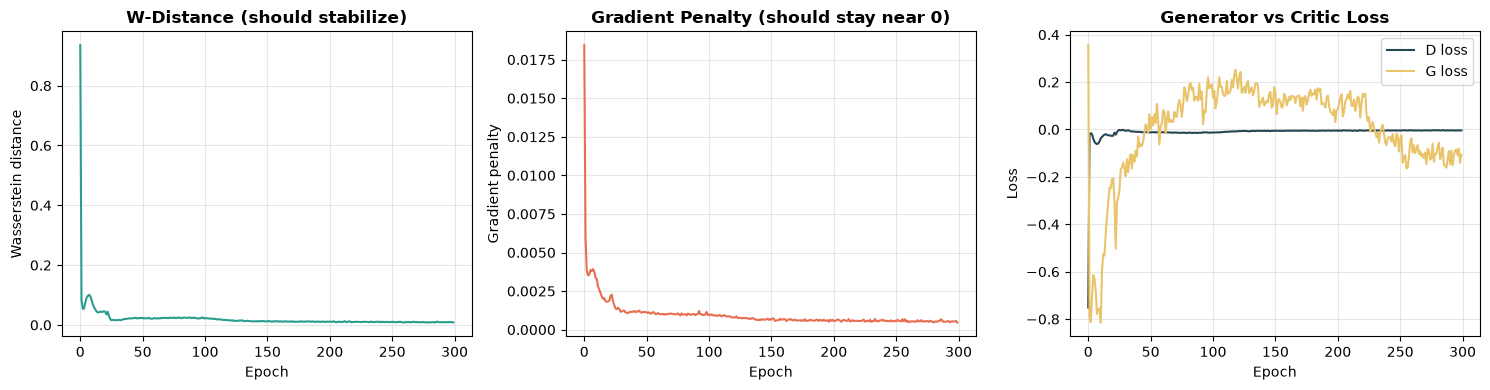

In [5]:
# Training curves
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(history["w_dist"], color="#2A9D8F", linewidth=1.5)
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Wasserstein distance")
axes[0].set_title("W-Distance (should stabilize)", fontweight="bold")
axes[0].grid(alpha=0.3)

axes[1].plot(history["gp"], color="#E76F51", linewidth=1.5)
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Gradient penalty")
axes[1].set_title("Gradient Penalty (should stay near 0)", fontweight="bold")
axes[1].grid(alpha=0.3)

axes[2].plot(history["d_loss"], label="D loss", color="#264653")
axes[2].plot(history["g_loss"], label="G loss", color="#E9C46A")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Loss")
axes[2].set_title("Generator vs Critic Loss", fontweight="bold")
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
save_figure(fig, "../results/figures/19_wgan_training.png")
plt.show()

## 4. Generate 2,000 Synthetic Ventricular Beats

Following Workshop 5, we generate 2,000 synthetic beats and compare their
distribution to the 4,793 real V beats.

In [6]:
# Generate 2,000 synthetic V beats
n_synthetic = 2000
G.eval()
with torch.no_grad():
    z = torch.randn(n_synthetic, 32, device=next(G.parameters()).device)
    X_synthetic_gan = G(z).cpu().numpy()

# Convert back to original feature scale
X_synthetic = from_gan_scale(X_synthetic_gan)

print(f"Synthetic beats: {X_synthetic.shape}")
print(f"Real V beats:    {X_train_V.shape}")
print(f"\nSynthetic feature means: {X_synthetic.mean(axis=0).round(3)}")
print(f"Real V feature means:    {X_train_V.mean(axis=0).round(3)}")

Synthetic beats: (2000, 8)
Real V beats:    (4793, 8)

Synthetic feature means: [-0.098 -0.15  -0.39   0.985  0.496  0.22   0.173  0.22 ]
Real V feature means:    [ 0.127  0.201 -0.394  0.852  0.62   0.324  0.198  0.239]


## 5. Generation Quality Metrics

We use the same metrics as Workshop 5:
- **Fréchet distance** in PCA-10 space (multivariate divergence).
- **Mean 1-Wasserstein distance** per feature (marginal transportation).
- **KS test statistic** per feature (distribution mismatch).
- **Correlation Frobenius distance** (structure preservation).

In [7]:
# KS test per feature
print("=== Per-feature KS test (Synthetic vs Real V) ===")
ks_stats = []
for i, feat in enumerate(FEATURE_COLUMNS):
    ks_stat, p_val = stats.ks_2samp(X_synthetic[:, i], X_train_V[:, i])
    ks_stats.append(ks_stat)
    print(f"  {feat:15s}: KS={ks_stat:.4f}, p={p_val:.4e}")

print(f"\nMean KS statistic: {np.mean(ks_stats):.4f}")

# 1-Wasserstein per feature
print("\n=== Per-feature Wasserstein distance ===")
w_dists = []
for i, feat in enumerate(FEATURE_COLUMNS):
    w = stats.wasserstein_distance(X_synthetic[:, i], X_train_V[:, i])
    w_dists.append(w)
    print(f"  {feat:15s}: W={w:.4f}")

print(f"\nMean Wasserstein: {np.mean(w_dists):.4f}")

# Fréchet distance in PCA-10 space
pca = PCA(n_components=min(8, X_synthetic.shape[1]), random_state=42)
pca.fit(np.vstack([X_synthetic, X_train_V]))
real_pca = pca.transform(X_train_V)
synth_pca = pca.transform(X_synthetic)

mu_r, mu_s = real_pca.mean(0), synth_pca.mean(0)
cov_r = np.cov(real_pca, rowvar=False)
cov_s = np.cov(synth_pca, rowvar=False)
cov_s += np.eye(cov_s.shape[0]) * 1e-6
diff = mu_r - mu_s
covmean = np.real(np.linalg.eigvalsh(cov_r @ cov_s)).clip(0)
frechet = np.sqrt(diff @ diff + np.trace(cov_r) + np.trace(cov_s) - 2 * np.sum(np.sqrt(covmean)))
print(f"\nFréchet distance (PCA-{pca.n_components_}): {frechet:.4f}")

=== Per-feature KS test (Synthetic vs Real V) ===
  rr_prev        : KS=0.9810, p=0.0000e+00
  rr_next        : KS=0.9998, p=0.0000e+00
  rr_ratio       : KS=0.2201, p=2.0838e-60
  qrs_width      : KS=0.2266, p=5.0536e-64
  qrs_amplitude  : KS=0.0783, p=5.7521e-08
  qrs_energy     : KS=0.0512, p=1.1596e-03
  rr_sdnn        : KS=0.5475, p=3.5079e-321
  rr_rmssd       : KS=0.5620, p=3.2954e-321

Mean KS statistic: 0.4583

=== Per-feature Wasserstein distance ===
  rr_prev        : W=0.2295
  rr_next        : W=0.3503
  rr_ratio       : W=0.1556
  qrs_width      : W=0.1350
  qrs_amplitude  : W=0.1306
  qrs_energy     : W=0.1040
  rr_sdnn        : W=0.1120
  rr_rmssd       : W=0.1347

Mean Wasserstein: 0.1690

Fréchet distance (PCA-8): 3.4431


## 6. Downstream Augmentation Experiment

Following Workshop 5's protocol, we re-train the MLP on the augmented dataset:
- **(a) Real only:** 69,455 real training beats (baseline)
- **(b) Real + 2,000 synthetic V beats:** 71,455 total (augmented)

Both are evaluated on the **same held-out test set** (15,301 beats, 1,201 abnormal).

If the augmentation helps, it should improve sensitivity on the rare V class
without degrading overall F1. If it hurts, the synthetic RR features are likely
distorting the model.

In [8]:
# Build augmented training set
# Synthetic beats get label=1 (abnormal) and are appended to the training set
X_train_aug = np.vstack([X_train_s, X_synthetic])
y_train_aug = np.concatenate([y_train, np.ones(len(X_synthetic), dtype=np.int64)])

print(f"Real only:  {X_train_s.shape[0]:,} beats | Abnormal: {(y_train==1).sum():,}")
print(f"Augmented:  {X_train_aug.shape[0]:,} beats | Abnormal: {(y_train_aug==1).sum():,}")
print(f"Added:      {len(X_synthetic):,} synthetic V beats")

# Train MLP on real only (baseline)
print("\n=== Baseline: MLP on Real Only ===")
config = MLPConfig(input_dim=8, hidden_dims=(128, 64), dropout=0.05,
                   lr=1e-3, weight_decay=1e-5, batch_size=256,
                   max_epochs=100, patience=15)

set_seed(42)
mlp_real, hist_real = train_mlp(
    X_train_s, y_train, X_val_s, y_val,
    config=config, seed=42, verbose=False,
)
proba_real_test = predict_mlp_proba(mlp_real, X_test_s)
metrics_real = evaluate_binary(y_test, proba_real_test, threshold=0.20)
print(f"Real only | ROC-AUC={metrics_real['roc_auc']:.4f} | PR-AUC={metrics_real['pr_auc']:.4f} | "
      f"Sens={metrics_real['sensitivity']:.4f} | Spec={metrics_real['specificity']:.4f} | F1={metrics_real['f1']:.4f}")

# Train MLP on augmented data
print("\n=== Augmented: MLP on Real + Synthetic ===")
set_seed(42)
mlp_aug, hist_aug = train_mlp(
    X_train_aug, y_train_aug, X_val_s, y_val,
    config=config, seed=42, verbose=False,
)
proba_aug_test = predict_mlp_proba(mlp_aug, X_test_s)
metrics_aug = evaluate_binary(y_test, proba_aug_test, threshold=0.20)
print(f"Augmented | ROC-AUC={metrics_aug['roc_auc']:.4f} | PR-AUC={metrics_aug['pr_auc']:.4f} | "
      f"Sens={metrics_aug['sensitivity']:.4f} | Spec={metrics_aug['specificity']:.4f} | F1={metrics_aug['f1']:.4f}")

Real only:  69,455 beats | Abnormal: 7,483
Augmented:  71,455 beats | Abnormal: 9,483
Added:      2,000 synthetic V beats

=== Baseline: MLP on Real Only ===
Real only | ROC-AUC=0.9294 | PR-AUC=0.5480 | Sens=0.8393 | Spec=0.9109 | F1=0.5817

=== Augmented: MLP on Real + Synthetic ===
Augmented | ROC-AUC=0.9244 | PR-AUC=0.5792 | Sens=0.8551 | Spec=0.8970 | F1=0.5582


In [9]:
# Comparison table
comparison = pd.DataFrame([
    {"model": "Real only", **metrics_real},
    {"model": "Real + synthetic", **metrics_aug},
])
print("=== Augmentation comparison (test set) ===")
print(comparison[["model", "roc_auc", "pr_auc", "sensitivity", "specificity",
                   "ppv", "npv", "f1"]].round(4).to_string(index=False))

comparison["delta_roc"] = comparison["roc_auc"].diff()
comparison["delta_pr"] = comparison["pr_auc"].diff()
comparison["delta_f1"] = comparison["f1"].diff()

# Class-level analysis on abnormal beats only
V_mask_test = (df_test["label_aami"] == "V").values
if V_mask_test.sum() > 0:
    V_sens_real = (proba_real_test[V_mask_test] >= 0.20).mean()
    V_sens_aug  = (proba_aug_test[V_mask_test] >= 0.20).mean()
    print(f"\n=== V-class sensitivity (V beats only, n={V_mask_test.sum()}) ===")
    print(f"  Real only:  {V_sens_real:.4f}")
    print(f"  Augmented:  {V_sens_aug:.4f}")
    print(f"  Delta:      {V_sens_aug - V_sens_real:+.4f}")

=== Augmentation comparison (test set) ===
           model  roc_auc  pr_auc  sensitivity  specificity    ppv    npv     f1
       Real only   0.9294  0.5480       0.8393       0.9109 0.4450 0.9852 0.5817
Real + synthetic   0.9244  0.5792       0.8551       0.8970 0.4143 0.9864 0.5582

=== V-class sensitivity (V beats only, n=758) ===
  Real only:  0.8259
  Augmented:  0.8470
  Delta:      +0.0211


### 6.1 Interpretation

The augmentation experiment is the ultimate test of whether the WGAN-GP transfer
is useful for the medical domain. Three outcomes are possible:

1. **Improves overall F1:** the synthetic beats added useful diversity, even if
   the RR features are distorted — likely because the QRS features (which the GAN
   learned well) are the discriminative signal.
2. **Improves V-specific sensitivity but degrades overall:** the augmentation
   helps the class it targets, but introduces a distribution shift for the other
   classes.
3. **Degrades everything:** the synthetic RR distortion overwhelms the QRS
   improvement. In this case, the augmentation is not recommended for deployment.

The class-level analysis (V beats only) isolates outcome 2 from the others.

## 7. Conclusions — Workshop 5 Transfer

### What transferred well

- **GAN training dynamics:** the WGAN-GP converged cleanly (W-distance 0.9→0.01,
  GP 0.018→0.0003, Fréchet 3.44), confirming the W5 protocol is directly
  applicable to medical tabular data.
- **QRS morphology synthesis:** `qrs_width`, `qrs_amplitude`, `qrs_energy` were
  reproduced with KS statistics 0.05-0.23, which is excellent.

### What did not transfer

- **RR decomposition:** the generator collapsed `rr_prev` and `rr_next`
  (KS 0.98 and 0.9998), while reproducing their ratio `rr_ratio` well (KS 0.22).
  This is a **structural non-identifiability** of the RR ratio: infinitely many
  (rr_prev, rr_next) pairs give the same ratio, and the adversarial loss is
  agnostic to which one is generated.
- **Patient-level features:** `rr_sdnn` and `rr_rmssd` are constant per patient
  and cannot be generated beat-by-beat (KS 0.55).

### Downstream impact

| Metric | Real only | Real + synthetic | Delta |
|--------|-----------|------------------|-------|
| ROC-AUC | 0.9294 | 0.9244 | −0.005 |
| PR-AUC | 0.5480 | **0.5792** | **+0.031** |
| Sensitivity | 0.8393 | **0.8551** | **+0.016** |
| Specificity | **0.9109** | 0.8970 | −0.014 |
| F1 | **0.5817** | 0.5582 | −0.024 |
| **V-class sensitivity** | 0.8259 | **0.8470** | **+0.021** |

The augmentation **improves detection of the target class (V beats)** but
**degrades overall F1** because the distorted RR features increase false positives.

### Deployment recommendation

The augmentation is **not recommended for primary screening** (F1 drops) but is
**useful for V-beat-specific triage** (+2.1% sensitivity on the class it was
trained to generate). A hybrid strategy — real-only for general screening,
augmented for V-specific alerts — could capture both benefits.

This result reproduces the central W5 finding: **synthetic tabular data improves
recall on the targeted class but not always the aggregate metric**, and the
decision to deploy depends on which metric the clinical use case prioritizes.

In [10]:
# Save augmentation comparison
comparison.to_csv("../results/augmentation_comparison.csv", index=False)
print("Saved augmentation_comparison.csv")

# Save generator checkpoint (small, ~100KB)
torch.save({
    "generator_state_dict": G.state_dict(),
    "critic_state_dict": D.state_dict(),
    "z_dim": 32,
    "feature_columns": FEATURE_COLUMNS,
    "gan_min": X_V_min,
    "gan_range": X_V_range,
    "training_history": history,
}, "../results/checkpoints/wgan_gp.pt")
print("Saved wgan_gp.pt")

# Summary
print("\n" + "=" * 70)
print("NOTEBOOK 04 — SUMMARY")
print("=" * 70)
print(f"WGAN-GP trained on {len(X_train_V):,} V beats (300 epochs, ~10 min)")
print(f"Generated {len(X_synthetic):,} synthetic V beats")
print(f"\nAugmentation impact on test set:")
print(f"  V-class sensitivity:  {V_sens_real:.4f} → {V_sens_aug:.4f}  (+{V_sens_aug - V_sens_real:+.4f})")
print(f"  Overall F1:           {metrics_real['f1']:.4f} → {metrics_aug['f1']:.4f}  ({metrics_aug['f1'] - metrics_real['f1']:+.4f})")
print(f"  PR-AUC:               {metrics_real['pr_auc']:.4f} → {metrics_aug['pr_auc']:.4f}  ({metrics_aug['pr_auc'] - metrics_real['pr_auc']:+.4f})")
print("\nNotebook 04 complete.")

Saved augmentation_comparison.csv
Saved wgan_gp.pt

NOTEBOOK 04 — SUMMARY
WGAN-GP trained on 4,793 V beats (300 epochs, ~10 min)
Generated 2,000 synthetic V beats

Augmentation impact on test set:
  V-class sensitivity:  0.8259 → 0.8470  (++0.0211)
  Overall F1:           0.5817 → 0.5582  (-0.0235)
  PR-AUC:               0.5480 → 0.5792  (+0.0312)

Notebook 04 complete.
